# LAB 1 - Bài 2 (Trang 30): Tiền xử lý dữ liệu môi trường nhà xưởng (tb_tracking.xlsx)
SV: Hồng Kim Dung - 6451071009

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt
import warnings; warnings.filterwarnings("ignore")

print("Hồng Kim Dung - 6451071009")
df = pd.read_excel("tb_tracking.xlsx", header=None)
print(df.shape)
df.head()

Hồng Kim Dung - 6451071009
(33340, 6)


,0,1,2,3,4,5
0,1.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:29
1,2.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:31
2,3.0,100.0,2.0,3.0,4.0,2016-12-20 12:52:35
3,4.0,100.0,2.0,3.0,400.0,2016-12-20 12:52:37
4,5.0,1.0,2.0,3.0,4.0,2016-12-20 13:02:01


## Câu a: Thêm tiêu đề cột

In [2]:
print("Hồng Kim Dung - 6451071009")

df.columns = ["id", "device_id", "co_level", "humidity", "temperature", "time"]
# Ba dòng cuối file là dòng thống kê (min, max, mean) và một dòng trống, không phải dữ liệu đo -> bỏ
print(df.tail(5))
df = df.iloc[:-4].copy()
df["time"] = pd.to_datetime(df["time"])
df.info()
df.head()

Hồng Kim Dung - 6451071009
            id     device_id     co_level      humidity   temperature  \
33335  33336.0      0.000000    31.500000     62.000000  2.004240e+06   
33336      NaN           NaN          NaN           NaN           NaN   
33337      1.0     -1.000000     0.000000      0.000000  0.000000e+00   
33338  33336.0  99005.000000  4030.000000  11030.000000  5.340310e+06   
33339  16668.5  97931.172516   181.704089   2127.562065  1.384405e+05   

                         time  
33335 2018-01-17 15:46:34.000  
33336                     NaT  
33337 2016-12-20 12:52:29.000  
33338 2018-01-17 15:46:34.000  
33339 2017-03-15 06:51:12.688  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33336 entries, 0 to 33335
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id           33336 non-null  float64       
 1   device_id    33336 non-null  float64       
 2   co_level     33336 non-null  floa

,id,device_id,co_level,humidity,temperature,time
0,1.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:29
1,2.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:31
2,3.0,100.0,2.0,3.0,4.0,2016-12-20 12:52:35
3,4.0,100.0,2.0,3.0,400.0,2016-12-20 12:52:37
4,5.0,1.0,2.0,3.0,4.0,2016-12-20 13:02:01


**Nhận xét:** đã đặt tên cột id, device_id, co_level, humidity, temperature, time. Cuối file có 1 dòng trống và 3 dòng thống kê tổng hợp nên được loại khỏi dữ liệu đo.

## Câu b: Loại bỏ dữ liệu trước ngày 03/01/2018

In [3]:
print("Hồng Kim Dung - 6451071009")

print("Trước khi lọc:", df.shape, "| từ", df["time"].min(), "đến", df["time"].max())
df = df[df["time"] >= "2018-01-03"].reset_index(drop=True)
print("Sau khi lọc:", df.shape, "| từ", df["time"].min(), "đến", df["time"].max())
df.head()

Hồng Kim Dung - 6451071009
Trước khi lọc: (33336, 6) | từ 2016-12-20 12:52:29 đến 2018-01-17 15:46:34
Sau khi lọc: (1917, 6) | từ 2018-01-03 13:11:07 đến 2018-01-17 15:46:34


,id,device_id,co_level,humidity,temperature,time
0,31420.0,1.0,2.0,3.0,4.0,2018-01-03 13:11:07
1,31421.0,1.0,2.0,3.0,4.0,2018-01-03 13:15:10
2,31422.0,99005.0,58.0,26.0,0.0,2018-01-03 13:17:30
3,31423.0,99005.0,58.0,26.0,0.0,2018-01-03 13:19:21
4,31424.0,99005.0,58.0,26.0,0.0,2018-01-03 13:24:17


## Câu c: Tách thời điểm đo trong ngày theo phút (minutes)

In [4]:
print("Hồng Kim Dung - 6451071009")

df["minutes"] = df["time"].dt.hour * 60 + df["time"].dt.minute
df[["time","minutes"]].head(10)

Hồng Kim Dung - 6451071009


,time,minutes
0,2018-01-03 13:11:07,791
1,2018-01-03 13:15:10,795
2,2018-01-03 13:17:30,797
3,2018-01-03 13:19:21,799
4,2018-01-03 13:24:17,804
5,2018-01-03 13:29:13,809
6,2018-01-03 13:34:10,814
7,2018-01-03 14:05:34,845
8,2018-01-03 14:10:43,850
9,2018-01-03 14:15:39,855


## Câu d: Đồ thị phân tán theo minutes

Hồng Kim Dung - 6451071009


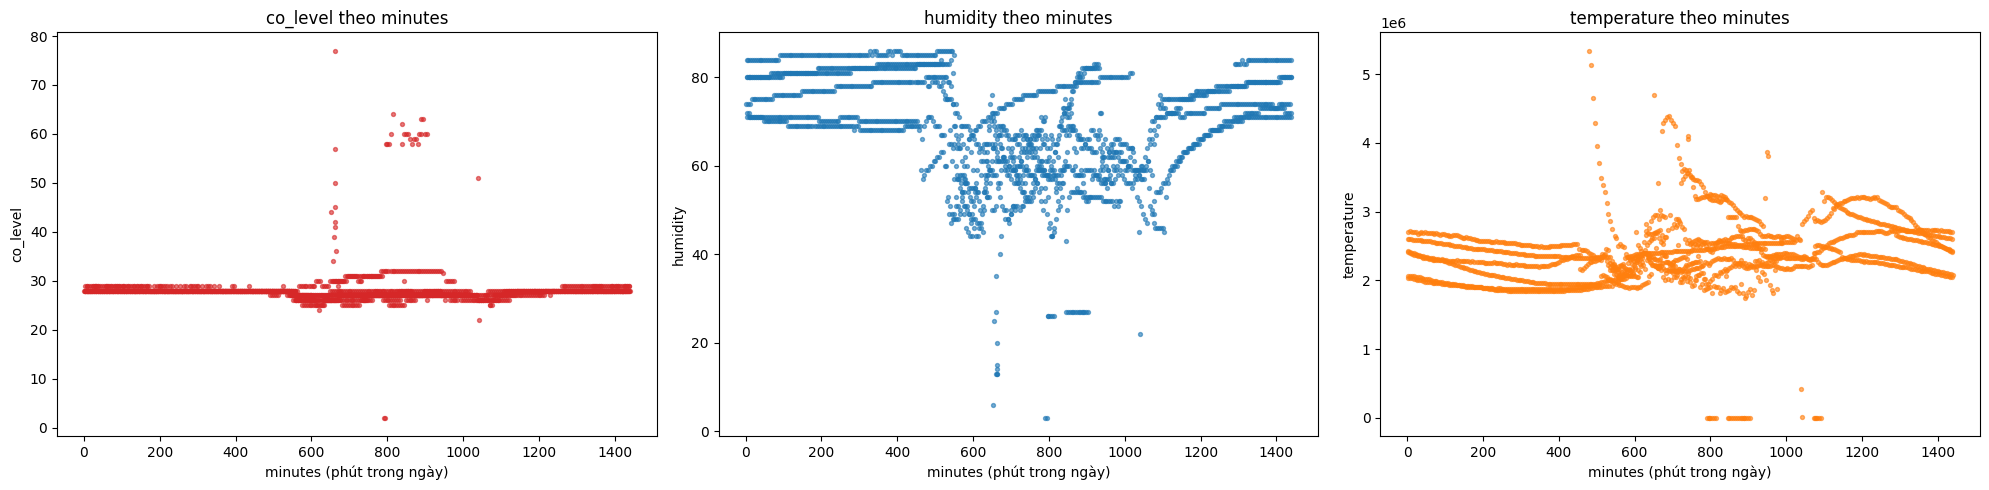

In [5]:
print("Hồng Kim Dung - 6451071009")

fig, ax = plt.subplots(1, 3, figsize=(20,5))
for a, col, color in zip(ax, ["co_level","humidity","temperature"], ["tab:red","tab:blue","tab:orange"]):
    a.scatter(df["minutes"], df[col], s=8, alpha=.6, color=color)
    a.set_title(f"{col} theo minutes"); a.set_xlabel("minutes (phút trong ngày)"); a.set_ylabel(col)
plt.tight_layout(); plt.show()

Hồng Kim Dung - 6451071009


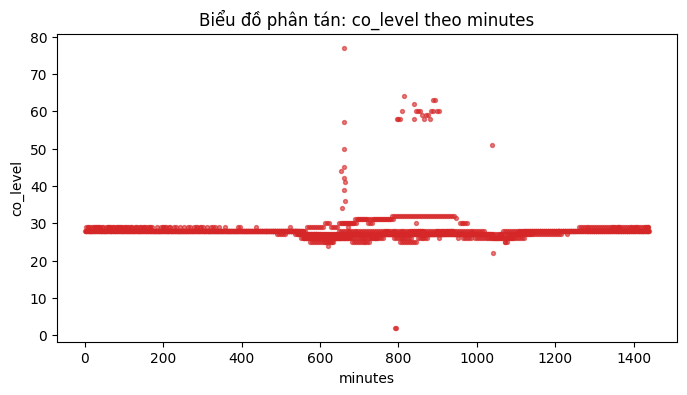

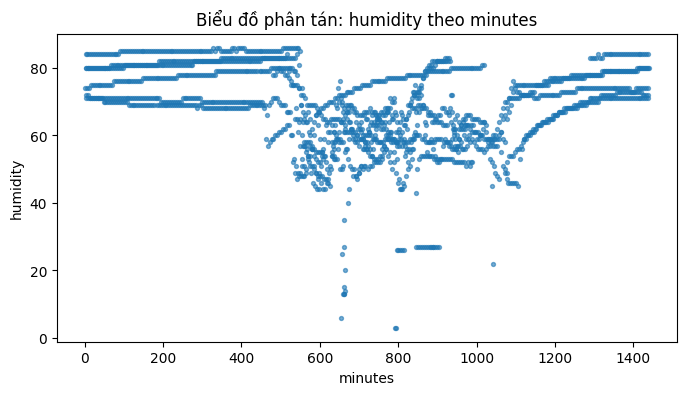

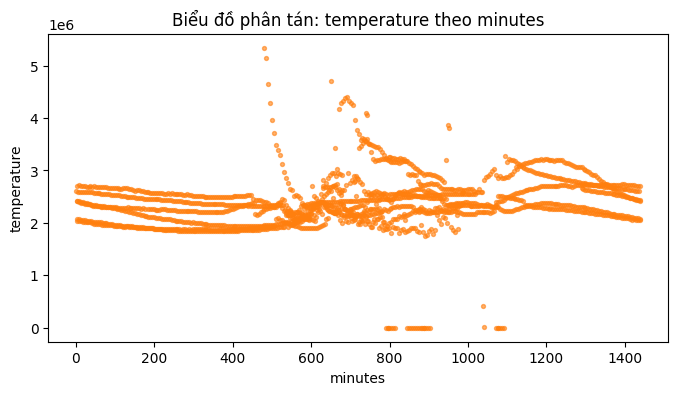

In [6]:
print("Hồng Kim Dung - 6451071009")

for col, color in zip(["co_level","humidity","temperature"], ["tab:red","tab:blue","tab:orange"]):
    plt.figure(figsize=(8,4)); plt.scatter(df["minutes"], df[col], s=8, alpha=.6, color=color)
    plt.title(f"Biểu đồ phân tán: {col} theo minutes"); plt.xlabel("minutes"); plt.ylabel(col); plt.show()